## Import Libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq, minimize
from sklearn.covariance import LedoitWolf
import config
from transaction_fee_helper import calculate_us_commission, calculate_crypto_commission

## Functions

In [2]:
def require_columns(frame, required, label):
    missing = sorted(set(required) - set(frame.columns))
    if missing:
        raise ValueError(f"{label} is missing required columns: {missing}")


def load_yahoo_prices(ticker):
    path = YAHOO_DIR / f"{ticker}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"Missing cleaned Yahoo input file: {path}")

    data = pd.read_csv(path, parse_dates=["Date"])
    price_columns = [
        "Date", "Open", "High", "Low", "Close", "Adj Close",
        "Volume", "Spread", "ADV_Dollars",
    ]
    require_columns(data, price_columns, str(path))
    data["Date"] = data["Date"].dt.normalize()
    if data["Date"].isna().any() or data["Date"].duplicated().any():
        raise ValueError(f"Invalid or duplicate dates in {path}")

    # Retain Monday-Friday observations only (including for cryptocurrency)
    data = data.loc[data["Date"].dt.dayofweek < 5, price_columns]
    data = data.sort_values("Date").copy()
    for column in price_columns[1:]:
        data[column] = pd.to_numeric(data[column], errors="coerce")

    return data


def load_selections(paths, allowed, cash_ticker):
    selections = {}
    dates_by_model = {}
    for model, path in paths.items():
        data = pd.read_csv(path, parse_dates=["Date"])
        require_columns(data, ["Date", "Algorithm", "Ticker", "Probability", "Selected_Assets"], str(path))
        if not data["Algorithm"].eq(model).all():
            raise ValueError(f"{path} contains an unexpected Algorithm value")
        if data["Date"].isna().any() or data.empty:
            raise ValueError(f"No valid rebalance dates in {path}")
        if data.dropna(subset=["Ticker"]).duplicated(["Date", "Ticker"]).any():
            raise ValueError(f"Duplicate selected assets in {path}")
        selected_by_date = {}
        for date, rows in data.groupby("Date", sort=True):
            tickers = rows["Ticker"].dropna().astype(str).tolist()
            expected = rows["Selected_Assets"].unique()
            if len(expected) != 1 or len(tickers) != int(expected[0]):
                raise ValueError(f"{model} {date.date()}: selected count does not match selected tickers")
            if cash_ticker in tickers or not set(tickers).issubset(allowed):
                raise ValueError(f"{model} {date.date()}: invalid or cash ticker in risky selection")
            selected_by_date[pd.Timestamp(date)] = tickers
        selections[model] = selected_by_date
        dates_by_model[model] = list(selected_by_date)
    if dates_by_model["XGBoost"] != dates_by_model["Logistic Regression"]:
        raise ValueError("LR and XGBoost test rebalance dates do not match")
    return selections, pd.DatetimeIndex(dates_by_model["XGBoost"])


def prepare_price_panels(market, risky, cash_ticker):
    spy_dates = pd.DatetimeIndex(
        market.loc[market["Ticker"].eq("SPY"), "Date"].sort_values().unique()
    )
    assets = market.loc[market["Ticker"].isin(risky)].copy()
    close = assets.pivot(index="Date", columns="Ticker", values="Adj_Close").reindex(spy_dates)
    # Only fill short, already-observed gaps, never manufacture an execution price
    close = close.ffill(limit=2).reindex(columns=risky)
    adjusted_open = assets.assign(
        Adjusted_Open=assets["Open"] * assets["Adj_Close"] / assets["Close"]
    ).pivot(index="Date", columns="Ticker", values="Adjusted_Open").reindex(index=spy_dates, columns=risky)
    cash_rows = market.loc[market["Ticker"].eq(cash_ticker)].set_index("Date").sort_index()
    cash_return = cash_rows["Daily_Total_Return"].reindex(spy_dates)
    cash_yield = cash_rows["Annual_Yield_Pct"].reindex(spy_dates)
    if cash_return.iloc[1:].isna().any() or cash_yield.isna().any():
        raise ValueError("Cash yield or daily cash return missing on the SPY calendar")
    if (cash_return.dropna() <= -1).any():
        raise ValueError("Invalid cash return")
    fee_history = assets.set_index(["Ticker", "Date"]).sort_index()
    return spy_dates, close, adjusted_open, cash_return, cash_yield, fee_history


def get_fee_context(date, tickers, fee_history):
    """Use costs known at the signal close; use conservative past values only for forced liquidations."""
    rows = []
    date = pd.Timestamp(date)
    if not tickers:
        return pd.DataFrame(columns=["Ticker", "Asset_Class", "Price", "Spread",
                                     "ADV_Dollars", "Cost_Fallback"]).set_index("Ticker")
    for ticker in tickers:
        history = fee_history.loc[ticker]
        if date not in history.index:
            raise ValueError(f"{ticker}: no price on signal date {date.date()}")
        row = history.loc[date]
        asset_class = str(row["Asset_Class"])
        spread, adv = float(row["Spread"]), float(row["ADV_Dollars"])
        fallback = False
        if asset_class.lower() != "crypto" and (
            not np.isfinite(spread) or spread < 0 or not np.isfinite(adv) or adv <= 0
        ):
            # A held position may need to be sold when today's quote is unavailable.
            # Estimate its cost from past valid quotes, never from future data.
            past = history.loc[:date, ["Spread", "ADV_Dollars"]].tail(252)
            past = past.loc[past["Spread"].ge(0) & past["ADV_Dollars"].gt(0)].dropna()
            if past.empty:
                raise ValueError(f"{ticker}: no historical cost data to liquidate the holding")
            spread = float(max(past["Spread"].iloc[-1], past["Spread"].quantile(.75)))
            adv = float(min(past["ADV_Dollars"].iloc[-1], past["ADV_Dollars"].quantile(.25)))
            fallback = True
        rows.append({
            "Ticker": ticker, "Asset_Class": asset_class,
            "Price": float(row["Close"]), "Spread": spread, "ADV_Dollars": adv,
            "Cost_Fallback": fallback,
        })
    return pd.DataFrame(rows).set_index("Ticker")


def ready_assets(date, risky, close_prices, fee_history):
    # Both forecasts and covariance need complete historical price windows.
    min_history = max(EXPECTED_RETURN_LOOKBACK, COVARIANCE_LOOKBACK) + 1
    window = close_prices.loc[:date, risky].tail(min_history)
    if len(window) != min_history:
        return []
    history_ready = window.notna().all(axis=0) & window.gt(0).all(axis=0)
    result = []
    for ticker in risky:
        if not history_ready.at[ticker]:
            continue
        row = fee_history.loc[(ticker, date)] if (ticker, date) in fee_history.index else None
        if row is None or row["Price_Available"] != True:
            continue
        if str(row["Asset_Class"]).lower() != "crypto" and row["Cost_Data_Ready"] != True:
            continue
        result.append(ticker)
    return result


def estimate_moments(date, chosen, close_prices, covariance_method):
    if not chosen:
        return np.empty(0), np.empty((0, 0))
    history_length = max(EXPECTED_RETURN_LOOKBACK, COVARIANCE_LOOKBACK) + 1
    history = close_prices.loc[:date, chosen].tail(history_length)
    if len(history) != history_length or history.isna().any().any() or (history <= 0).any().any():
        raise ValueError(f"{date.date()}: incomplete historical window for {chosen}")
    p = history.to_numpy(float)
    mu60 = np.expm1(
        (HORIZON / EXPECTED_RETURN_LOOKBACK)
        * np.log(p[-1] / p[-(EXPECTED_RETURN_LOOKBACK + 1)])
    )
    observations = (
        history.pct_change(fill_method=None)
        .tail(COVARIANCE_LOOKBACK)
        .to_numpy(float)
    )
    if covariance_method == "Sample":
        cov_daily = np.atleast_2d(np.cov(observations, rowvar=False, ddof=1))
    elif covariance_method == "Ledoit_Wolf":
        lw = LedoitWolf().fit(observations)
        cov_daily = lw.covariance_ * (len(observations) / (len(observations) - 1))
    else:
        raise ValueError(f"Unknown covariance estimator: {covariance_method}")
    cov60 = HORIZON * np.atleast_2d(cov_daily)
    cov60 = 0.5 * (cov60 + cov60.T)
    return mu60, cov60


def fee_amount_and_slope(trade_dollars, ticker, context, monthly_crypto_volume):
    """Same spread, quadratic impact and IBKR commission schedules as transaction_fee_helper.py."""
    trade = abs(float(trade_dollars))
    if trade < 1e-10:
        return 0.0, 0.0
    sign = np.sign(trade_dollars)
    c = context.loc[ticker]
    category = str(c["Asset_Class"]).strip().lower()
    if category == "crypto":
        commission = calculate_crypto_commission(trade, monthly_crypto_volume)
        rate = next(rate for limit, rate in [(100_000., 0.0018), (1_000_000., 0.0015), (np.inf, 0.0012)]
                    if monthly_crypto_volume <= limit)
        raw = rate * trade
        slope = 0.01 if 0.01 * trade < max(raw, 1.75) else (rate if raw > 1.75 else 0.0)
        return float(commission), float(slope * sign)
    price = float(c["Price"])
    spread = float(c["Spread"])
    adv = float(c["ADV_Dollars"])
    if not (np.isfinite(price) and price > 0 and np.isfinite(spread) and spread >= 0
            and np.isfinite(adv) and adv > 0):
        raise ValueError(f"{ticker}: invalid point-in-time transaction-cost inputs")
    commission = calculate_us_commission(trade, price)
    share_rate = 0.005 / price
    raw = share_rate * trade
    slope_fee = .01 if .01 * trade < max(raw, 1.0) else (share_rate if raw > 1.0 else 0.0)
    amount = 0.5 * spread * trade + MARKET_IMPACT_COEFFICIENT * trade**2 / adv + commission
    slope = (0.5 * spread + 2 * MARKET_IMPACT_COEFFICIENT * trade / adv + slope_fee) * sign
    return float(amount), float(slope)


def transaction_costs(trades, context, monthly_crypto_volume, breakdown=False):
    total = 0.0
    slopes = {}
    details = []
    for ticker, trade in trades.items():
        if abs(float(trade)) < 1e-10:
            continue
        cost, slope = fee_amount_and_slope(trade, ticker, context, monthly_crypto_volume)
        total += cost
        slopes[ticker] = slope
        if breakdown:
            category = str(context.at[ticker, "Asset_Class"]).strip().lower()
            spread_cost = (.5 * float(context.at[ticker, "Spread"]) * abs(trade)
                           if category != "crypto" else 0.0)
            impact_cost = (MARKET_IMPACT_COEFFICIENT * trade**2 / float(context.at[ticker, "ADV_Dollars"])
                           if category != "crypto" else 0.0)
            details.append({
                "Ticker": ticker, "Trade_USD": float(trade), "Spread_Cost": spread_cost,
                "Market_Impact_Cost": impact_cost,
                "IBKR_Commission": cost - spread_cost - impact_cost,
                "Total_Cost": cost,
                "Cost_Fallback": bool(context.at[ticker, "Cost_Fallback"]),
            })
    return total, slopes, details


def optimize_direct_utility(chosen, current_dollars, portfolio_value, mu60, cov60, cash60,
                            fee_context, monthly_crypto_volume, risk_aversion=3.0, starts=12):
    if not chosen:
        return pd.Series(dtype=float)
    chosen = list(chosen)
    excess = np.asarray(mu60, float) - float(cash60)
    n = len(chosen)
    cov60 = np.asarray(cov60, float)
    def evaluate(weights):
        targets = {t: float(weights[i] * portfolio_value) for i, t in enumerate(chosen)}
        union = set(current_dollars).union(chosen)
        trades = {t: targets.get(t, 0.0) - current_dollars.get(t, 0.0) for t in union}
        costs, gradients, _ = transaction_costs(trades, fee_context, monthly_crypto_volume)
        utility = excess @ weights - .5 * risk_aversion * (weights @ cov60 @ weights) - costs / portfolio_value
        jac = -excess + risk_aversion * (cov60 @ weights)
        jac += np.array([gradients.get(t, 0.0) for t in chosen])
        # fee gradient: d(cost / V)/dw = (dcost/dtrade) * V / V
        return -float(utility), jac

    limit = min(1.0, 0.2 * n)
    seeds = [np.zeros(n), np.full(n, limit / n)]
    current = np.array([max(0.0, current_dollars.get(t, 0.0) / portfolio_value) for t in chosen])
    current = np.minimum(current, 0.2)
    seeds.append(current if current.sum() <= 1.0 else current / current.sum())
    rng = np.random.default_rng(42 + n)
    for _ in range(max(0, starts - len(seeds))):
        seed = rng.dirichlet(np.ones(n)) * rng.uniform(0.0, limit)
        seeds.append(seed)
    constraint = {"type": "ineq", "fun": lambda w: 1.0 - w.sum(), "jac": lambda w: -np.ones_like(w)}
    best = None
    for seed in seeds[:starts]:
        result = minimize(
            fun=lambda w: evaluate(w)[0], x0=seed, jac=lambda w: evaluate(w)[1],
            method="SLSQP", bounds=[(0.0, 0.2)] * n, constraints=[constraint],
            options={"maxiter": 400, "ftol": 1e-9, "disp": False},
        )
        weights = np.clip(result.x, 0.0, 0.2)
        if weights.sum() > 1.0 + 1e-7 or not np.isfinite(weights).all():
            continue
        if weights.sum() > 1.0:
            weights /= weights.sum()  # Remove harmless optimizer equality-tolerance overshoot.
        score = evaluate(weights)[0]
        if np.isfinite(score) and (best is None or score < best[0]):
            best = (score, weights)
    if best is None:
        raise ValueError("No feasible portfolio found by direct-utility optimization")
    return pd.Series(best[1], index=chosen, dtype=float)


def equal_weight_targets(chosen):
    if not chosen:
        return pd.Series(dtype=float)
    weight = min(0.2, 1.0 / len(chosen))
    return pd.Series(weight, index=list(chosen), dtype=float)


def execute_trades(shares, cash_balance, target_weights, open_prices, fee_context,
                   monthly_crypto_volume, strategy, execution_date, signal_date):
    """Solve the post-fee investment budget exactly, including turnover costs."""
    held = {t: float(q * open_prices.at[t]) for t, q in shares.items() if abs(q) > 1e-12}
    pre_value = cash_balance + sum(held.values())
    if pre_value <= 0:
        raise ValueError("Nonpositive portfolio value before trade")
    target = target_weights[target_weights.gt(1e-10)].to_dict()
    if sum(target.values()) > 1.0:
        scale = sum(target.values())
        target = {ticker: weight / scale for ticker, weight in target.items()}

    def proposed_trades(cost_guess):
        target_dollars = {t: w * (pre_value - cost_guess) for t, w in target.items()}
        trades = {t: target_dollars.get(t, 0.0) - held.get(t, 0.0)
                  for t in set(held) | set(target)}
        return target_dollars, trades

    def budget_equation(cost_guess):
        _, trades = proposed_trades(cost_guess)
        total_cost, _, _ = transaction_costs(trades, fee_context, monthly_crypto_volume)
        return cost_guess - total_cost

    max_cost = pre_value * (1.0 - 1e-12)
    if budget_equation(max_cost) < 0:
        raise ValueError(f"{strategy}: transaction costs exceed the investable portfolio value")
    cost = brentq(budget_equation, 0.0, max_cost, xtol=1e-9)
    target_dollars, trades = proposed_trades(cost)
    actual_cost, _, details = transaction_costs(
        trades, fee_context, monthly_crypto_volume, breakdown=True
    )
    new_cash = cash_balance - sum(trades.values()) - actual_cost
    if new_cash < -1e-5:
        raise ValueError(f"{strategy}: transaction costs exceed available cash at {execution_date.date()}")
    new_shares = {t: v / float(open_prices.at[t])
                  for t, v in target_dollars.items() if v > 1e-9}
    for item in details:
        item.update({"Date": execution_date, "Signal_Date": signal_date, "Strategy": strategy})
    month_volume = monthly_crypto_volume + sum(
        abs(v) for t, v in trades.items()
        if str(fee_context.at[t, "Asset_Class"]).lower() == "crypto"
    )
    return new_shares, max(0.0, new_cash), actual_cost, month_volume, details


def backtest_strategy(strategy, selections, dates, calendar, close, adjusted_open,
                      cash_return, cash_yield, fee_history, risky, cash_ticker,
                      covariance_method, risk_aversion, starts, initial_capital):
    first_signal = dates[0]
    # Value the final holdings through the latest available SPY session,
    # without trading again after the final rebalance.
    active_days = calendar[calendar >= first_signal]
    optimized = strategy.endswith("_Optimized")
    if strategy.startswith("XGBoost"):
        selected = selections["XGBoost"]
    elif strategy.startswith("Logistic_Regression"):
        selected = selections["Logistic Regression"]
    else:
        selected = None

    shares = {}
    cash_balance = float(initial_capital)
    month_volume = 0.0
    month_key = None
    pending = None
    nav_rows, weight_rows, trades_rows, rebalance_rows = [], [], [], []
    for day in active_days:
        if day != first_signal:
            if (day.year, day.month) != month_key:
                month_key, month_volume = (day.year, day.month), 0.0
            cash_balance *= 1.0 + float(cash_return.loc[day])
            if pending is not None:
                target, context, signal_day, source_count = pending
                required = set(shares) | set(target[target.gt(1e-10)].index)
                opening = adjusted_open.loc[day, list(required)]
                if opening.isna().any() or (opening <= 0).any():
                    raise ValueError(f"{strategy} {day.date()}: missing next-session adjusted open")
                # The decision uses signal-close prices. Actual order commissions
                # use the unadjusted execution open (known when the order fills).
                execution_context = context.copy()
                for ticker in required:
                    raw_open = float(fee_history.loc[(ticker, day), "Open"])
                    if not np.isfinite(raw_open) or raw_open <= 0:
                        raise ValueError(f"{ticker}: missing raw execution open on {day.date()}")
                    execution_context.at[ticker, "Price"] = raw_open
                shares, cash_balance, fee, month_volume, breakdown = execute_trades(
                    shares, cash_balance, target, opening, execution_context, month_volume,
                    strategy, day, signal_day,
                )
                trades_rows.extend(breakdown)
                value_at_open_after_fees = cash_balance + sum(shares[t] * opening.at[t] for t in shares)
                rebalance_rows.append({
                    "Strategy": strategy, "Signal_Date": signal_day, "Execution_Date": day,
                    "Selected_Assets": source_count, "Held_Assets": len(shares),
                    "Cash_Weight": cash_balance / value_at_open_after_fees,
                    "Transaction_Cost_USD": fee,
                })
                for t, weight in target.items():
                    if weight > 1e-10:
                        weight_rows.append({"Strategy": strategy, "Signal_Date": signal_day,
                                            "Execution_Date": day, "Ticker": t, "Target_Weight": float(weight)})
                weight_rows.append({"Strategy": strategy, "Signal_Date": signal_day,
                                    "Execution_Date": day, "Ticker": cash_ticker,
                                    "Target_Weight": float(1.0 - target.sum())})
                pending = None

        day_close = close.loc[day]
        nav = cash_balance + sum(float(q) * float(day_close.at[t]) for t, q in shares.items())
        if not np.isfinite(nav) or nav <= 0:
            raise ValueError(f"{strategy} {day.date()}: invalid NAV")
        nav_rows.append({"Date": day, "Strategy": strategy, "NAV": nav,
                         "Cash_Weight": cash_balance / nav, "Risky_Weight": 1.0 - cash_balance / nav})

        if day in dates:
            held_dollars = {t: float(q * day_close.at[t]) for t, q in shares.items()}
            if selected is not None:
                choices = selected[day]
            elif strategy in {"Full_Universe_Optimized", "Equal_Weight_48_Buy_Hold", "SPY_Buy_Hold"}:
                choices = ["SPY"] if strategy == "SPY_Buy_Hold" else risky
            else:
                raise ValueError(f"Unknown strategy: {strategy}")
            is_buy_hold = strategy in {"Equal_Weight_48_Buy_Hold", "SPY_Buy_Hold"}
            if is_buy_hold and day != first_signal:
                continue
            if is_buy_hold:
                eligible = list(choices)
                target = (pd.Series({"SPY": 1.0}) if strategy == "SPY_Buy_Hold"
                          else pd.Series(1.0 / len(eligible), index=eligible, dtype=float))
            else:
                ready = set(ready_assets(day, risky, close, fee_history))
                eligible = [t for t in choices if t in ready]
                if optimized and eligible:
                    mu60, cov60 = estimate_moments(day, eligible, close, covariance_method)
                    calendar_end = calendar[calendar.get_loc(day) + 60]
                    calendar_days = (calendar_end - day).days
                    annual_yield = float(cash_yield.loc[day])
                    cash60 = (1.0 + annual_yield / 100.0)**(calendar_days / 365.0) - 1.0
                else:
                    mu60, cov60, cash60 = None, None, None
                # Previously held positions must remain in the cost context to charge liquidation costs.
                context = get_fee_context(day, list(dict.fromkeys(eligible + list(shares))), fee_history)
                if optimized:
                    target = optimize_direct_utility(
                        eligible, held_dollars, nav, mu60, cov60, cash60,
                        context, month_volume, risk_aversion=risk_aversion, starts=starts,
                    )
                else:
                    target = equal_weight_targets(eligible)
            if is_buy_hold:
                context = get_fee_context(day, eligible, fee_history)
            pending = (target, context, day, len(choices))

    return (pd.DataFrame(nav_rows), pd.DataFrame(weight_rows),
            pd.DataFrame(trades_rows), pd.DataFrame(rebalance_rows))


def summarize_performance(nav, trades, initial_capital, cash_return, cash_ticker):
    rows = []
    for strategy, group in nav.groupby("Strategy", sort=False):
        group = group.sort_values("Date")
        values = group["NAV"].to_numpy(float)
        returns = pd.Series(values).pct_change().iloc[1:].to_numpy()
        rf = cash_return.reindex(group["Date"].iloc[1:]).to_numpy(float)
        excess = returns - rf
        volatility = float(np.std(returns, ddof=1) * np.sqrt(252)) if len(returns) > 1 else np.nan
        sharpe = (float(np.mean(excess) / np.std(excess, ddof=1) * np.sqrt(252))
                  if len(excess) > 1 and np.std(excess, ddof=1) > 0 else np.nan)
        years = (group["Date"].iloc[-1] - group["Date"].iloc[0]).days / 365.25
        drawdown = values / np.maximum.accumulate(values) - 1.0
        total_costs = (float(trades.loc[trades["Strategy"].eq(strategy), "Total_Cost"].sum())
                       if not trades.empty else 0.0)
        rows.append({
            "Strategy": strategy, "Total_Return": values[-1] / initial_capital - 1.0,
            "CAGR": (values[-1] / initial_capital)**(1.0 / years) - 1.0,
            "Annualized_Volatility": volatility, "Annualized_Sharpe": sharpe,
            "Max_Drawdown": float(drawdown.min()), "Transaction_Cost_USD": total_costs,
            "Average_Cash_Weight": float(group["Cash_Weight"].mean()),
            "Final_NAV": float(values[-1]),
        })
    return pd.DataFrame(rows)


## Load Configuration and Investable Universe

In [3]:
PROJECT_ROOT = config.INPUT_DATA_DIR.parent
YAHOO_DIR = config.INPUT_DATA_DIR / "yahoo"
FRED_DIR = config.INPUT_DATA_DIR / "fred"
UNIVERSE_FILE = config.UNIVERSE_FILE
CASH_DAY_COUNT = 365.0  # number of days in a year for cash return calculation

universe = pd.read_csv(UNIVERSE_FILE)
require_columns(universe, ["Ticker", "Asset Class", "Source"], str(UNIVERSE_FILE))
universe["Ticker"] = universe["Ticker"].astype("string").str.strip()
universe["Asset Class"] = universe["Asset Class"].astype("string").str.strip()
universe["Source"] = universe["Source"].astype("string").str.strip().str.lower()

yahoo_universe = universe.loc[
    universe["Source"].str.contains("yahoo", case=False, regex=False),
    ["Ticker", "Asset Class"],
].copy()

cash_universe = universe.loc[
    universe["Source"].str.contains("fred", case=False, regex=False)
    & universe["Asset Class"].str.contains("cash", case=False, regex=False)
]

CASH_TICKER = cash_universe["Ticker"].iloc[0]
CASH_ASSET_CLASS = cash_universe["Asset Class"].iloc[0]

asset_parts = []
for ticker, asset_class in yahoo_universe.itertuples(index=False, name=None):
    data = load_yahoo_prices(ticker).rename(columns={"Adj Close": "Adj_Close"})
    if data.empty:
        raise ValueError(f"No observations found for {ticker}")

    data["Ticker"] = ticker
    data["Asset_Class"] = asset_class
    data["Daily_Total_Return"] = data["Adj_Close"].pct_change(fill_method=None)
    data["Dollar_Volume"] = data["Close"] * data["Volume"]
    data["Price_Available"] = data["Adj_Close"].gt(0) & data["Close"].gt(0)
    data["Cost_Data_Ready"] = (
        data["Price_Available"]
        & data["High"].gt(0) & data["Low"].gt(0)
        & data["High"].ge(data["Low"]) & data["Volume"].gt(0)
        & data["Spread"].ge(0) & np.isfinite(data["Spread"])
        & data["ADV_Dollars"].gt(0) & np.isfinite(data["ADV_Dollars"])
    )
    asset_parts.append(data)

asset_data = pd.concat(asset_parts, ignore_index=True)
spy_dates = pd.DatetimeIndex(asset_data.loc[asset_data["Ticker"].eq("SPY"), "Date"].sort_values().unique())

SIGNAL_FILES = {
    "Logistic Regression": PROJECT_ROOT / "classification_results" / "logistic_regression" / "selected_strategy_test_results.csv",
    "XGBoost": PROJECT_ROOT / "classification_results" / "xgboost" / "selected_strategy_test_results.csv",
}
OUTPUT_DIR = PROJECT_ROOT / "portfolio_results"

INITIAL_CAPITAL = config.INITIAL_CAPITAL
RISK_AVERSION = config.RISK_AVERSION
EXPECTED_RETURN_LOOKBACK = config.EXPECTED_RETURN_LOOKBACK
COVARIANCE_LOOKBACK = config.COVARIANCE_LOOKBACK
DIRECT_STARTS = config.DIRECT_STARTS
MAX_WEIGHT = config.MAX_WEIGHT
MARKET_IMPACT_COEFFICIENT = config.MARKET_IMPACT_COEFFICIENT
HORIZON = config.FORWARD_HORIZON
COVARIANCE_METHODS = ("Sample", "Ledoit_Wolf")
RISKY_TICKERS = yahoo_universe["Ticker"].tolist()

print(f"Risky instruments: {len(RISKY_TICKERS)}; cash proxy: {CASH_TICKER}")

Risky instruments: 48; cash proxy: DGS3MO


## Add Cash Proxy

In [4]:
cash_path = FRED_DIR / f"{CASH_TICKER}.csv"
if not cash_path.is_file():
    raise FileNotFoundError(f"Missing cash-proxy series: {cash_path}")

cash_yields = pd.read_csv(cash_path, parse_dates=["Date"])
require_columns(cash_yields, ["Date", CASH_TICKER], str(cash_path))
cash_yields["Date"] = cash_yields["Date"].dt.normalize()
cash_yields[CASH_TICKER] = pd.to_numeric(cash_yields[CASH_TICKER], errors="coerce")
cash_yields = cash_yields.dropna(subset=["Date", CASH_TICKER]).sort_values("Date")
if cash_yields.empty or cash_yields["Date"].duplicated().any():
    raise ValueError(f"Missing or duplicate cash yield observations in {cash_path}")

cash_calendar = pd.merge_asof(
    pd.DataFrame({"Date": spy_dates}),
    cash_yields[["Date", CASH_TICKER]].rename(columns={CASH_TICKER: "Annual_Yield_Pct"}),
    on="Date",
    direction="backward",
)

calendar_days = cash_calendar["Date"].diff().dt.days
cash_calendar["Daily_Total_Return"] = (
    (1.0 + cash_calendar["Annual_Yield_Pct"].shift(1) / 100.0)
    .pow(calendar_days / CASH_DAY_COUNT) - 1.0
)

cash_data = cash_calendar[["Date", "Annual_Yield_Pct", "Daily_Total_Return"]].copy()
cash_data["Ticker"] = CASH_TICKER
cash_data["Asset_Class"] = CASH_ASSET_CLASS

## Load Portfolio Market Data and Classification Signals

In [5]:
columns = [
    "Date", "Ticker", "Asset_Class", "Open", "High", "Low", "Close",
    "Adj_Close", "Volume", "Dollar_Volume", "Spread", "ADV_Dollars",
    "Daily_Total_Return", "Annual_Yield_Pct", "Price_Available", "Cost_Data_Ready",
]
# Cash has no tradable OHLCV prices or ETF-style liquidity/eligibility checks
portfolio_market_data = pd.concat([asset_data, cash_data], ignore_index=True)
portfolio_market_data = (
    portfolio_market_data.reindex(columns=columns)
    .sort_values(["Date", "Ticker"])
    .reset_index(drop=True)
)

# Retain one calendar year of history before the configured start date
export_start = pd.Timestamp(config.START_DATE) - pd.DateOffset(years=1)
portfolio_market_data = portfolio_market_data.loc[
    portfolio_market_data["Date"].ge(export_start)
].reset_index(drop=True)

# Consume the unified market data directly, without an intermediate CSV.
selections, signal_dates = load_selections(SIGNAL_FILES, set(RISKY_TICKERS), CASH_TICKER)
calendar, close_prices, adjusted_open, cash_return, cash_yield, fee_history = prepare_price_panels(
    portfolio_market_data, RISKY_TICKERS, CASH_TICKER
)

primary_horizon_end = calendar[calendar.get_loc(signal_dates[-1]) + HORIZON]
final_valuation_date = calendar[-1]
print(f"Prepared {len(portfolio_market_data):,} market/cash observations in memory")
print(f"Rebalances: {len(signal_dates)}; {signal_dates[0].date()} to {signal_dates[-1].date()}")
print(f"Primary 60-session horizon ends: {primary_horizon_end.date()}")
print(f"Valuation ends: {final_valuation_date.date()} (no additional rebalances)")
for model, by_date in selections.items():
    print(f"{model}: {sum(len(v) for v in by_date.values())} selected asset-date observations; "
          f"{sum(len(v) == 0 for v in by_date.values())} cash-only rebalances")

Prepared 237,146 market/cash observations in memory
Rebalances: 20; 2022-01-03 to 2026-07-22
Primary 60-session horizon ends: 2026-10-15
Valuation ends: 2026-11-10 (no additional rebalances)
Logistic Regression: 237 selected asset-date observations; 3 cash-only rebalances
XGBoost: 212 selected asset-date observations; 1 cash-only rebalances


## Construct and Backtest Portfolios

At each S04 signal close, estimate the **60-session expected return** using raw momentum over `config.EXPECTED_RETURN_LOOKBACK` trading sessions: $\hat\mu_{60}=(P_t/P_{t-L})^{60/L}-1$, where $L$ is the expected-return lookback. The covariance estimate uses `config.COVARIANCE_LOOKBACK` historical daily returns, scaled by 60. Compare the sample covariance with Ledoit–Wolf shrinkage; all other settings stay fixed.

The direct utility objective is $w^\top(\hat\mu_{60}-r_{f,60}\mathbf{1})-\frac{3}{2}w^\top\hat\Sigma_{60}w-TC/V$, subject to $0\leq w_i\leq0.20$ and $\sum_i w_i\leq1$. Remaining weight is held as cash. The optimizer uses 12 initializations. S04's realized target labels and forward returns are not used to make trading decisions.

Orders are modeled at the next SPY session's **adjusted-open price proxy**, with estimated spread, market impact and IBKR commissions deducted. Target weights may drift until the next rebalance. The 20% limit applies to portfolio-construction strategies, not to buy-and-hold benchmarks. The cash return ending on the execution date is credited before opening trades, which approximates the timing of within-day cash accrual.

**Valuation extension:** The primary 20-rebalance, 60-session test finishes at the horizon of the final S04 signal. After that date, all portfolios continue to be valued using their existing positions and cash balances until the last available SPY trading date. There are no additional trades or classification decisions during this extension. The evaluation displays both the primary-horizon and extended results separately.

In [6]:
strategies = [
    "XGBoost_Optimized",
    "Logistic_Regression_Optimized",
    "Full_Universe_Optimized",
    "XGBoost_Equal_Weight",
    "Logistic_Regression_Equal_Weight",
    "Equal_Weight_48_Buy_Hold",
    "SPY_Buy_Hold",
]

nav_parts = []
weights_parts = []
trade_parts = []
rebalance_parts = []

for covariance_method in COVARIANCE_METHODS:
    for strategy in strategies:
        # Nonoptimized strategies are identical under both covariance estimators.
        if covariance_method != COVARIANCE_METHODS[0] and not strategy.endswith("_Optimized"):
            continue
        name = f"{strategy}_{covariance_method}" if strategy.endswith("_Optimized") else strategy
        print(f"Backtesting: {name}")
        nav, weights, trades, rebalances = backtest_strategy(
            strategy, selections, signal_dates, calendar, close_prices,
            adjusted_open, cash_return, cash_yield, fee_history,
            RISKY_TICKERS, CASH_TICKER,
            covariance_method=covariance_method,
            risk_aversion=RISK_AVERSION, starts=DIRECT_STARTS,
            initial_capital=INITIAL_CAPITAL,
        )
        for frame in (nav, weights, trades, rebalances):
            if not frame.empty:
                frame["Strategy"] = name
        nav_parts.append(nav)
        if not weights.empty:
            weights_parts.append(weights)
        if not trades.empty:
            trade_parts.append(trades)
        if not rebalances.empty:
            rebalance_parts.append(rebalances)

portfolio_nav = pd.concat(nav_parts, ignore_index=True)
portfolio_weights = pd.concat(weights_parts, ignore_index=True)
portfolio_trades = (pd.concat(trade_parts, ignore_index=True) if trade_parts
                    else pd.DataFrame(columns=["Date", "Strategy", "Ticker", "Trade_USD", "Total_Cost"]))
portfolio_rebalances = pd.concat(rebalance_parts, ignore_index=True)

portfolio_nav = portfolio_nav.sort_values(["Strategy", "Date"]).reset_index(drop=True)
portfolio_nav["Daily_Return"] = portfolio_nav.groupby("Strategy")["NAV"].pct_change()
performance_summary = summarize_performance(portfolio_nav, portfolio_trades, INITIAL_CAPITAL, cash_return, CASH_TICKER)

Backtesting: XGBoost_Optimized_Sample
Backtesting: Logistic_Regression_Optimized_Sample
Backtesting: Full_Universe_Optimized_Sample
Backtesting: XGBoost_Equal_Weight
Backtesting: Logistic_Regression_Equal_Weight
Backtesting: Equal_Weight_48_Buy_Hold
Backtesting: SPY_Buy_Hold
Backtesting: XGBoost_Optimized_Ledoit_Wolf
Backtesting: Logistic_Regression_Optimized_Ledoit_Wolf
Backtesting: Full_Universe_Optimized_Ledoit_Wolf


## Evaluation

Performance Evaluation with last day: 2026-11-10


,Strategy,Total_Return,CAGR,Annualized_Volatility,Annualized_Sharpe,Max_Drawdown,Transaction_Cost_USD,Average_Cash_Weight,Final_NAV
8,XGBoost_Optimized_Ledoit_Wolf,0.6164,0.1040,0.1295,0.5189,-0.1894,4418.2560,0.3715,161639.5148
9,XGBoost_Optimized_Sample,0.6164,0.1040,0.1295,0.5189,-0.1894,4418.2560,0.3715,161639.5148
2,Full_Universe_Optimized_Sample,0.8103,0.1301,0.2033,0.5069,-0.1854,6359.1657,0.0506,181029.8569
3,Logistic_Regression_Equal_Weight,0.5443,0.0937,0.1093,0.5066,-0.1458,1814.2825,0.1678,154434.2623
1,Full_Universe_Optimized_Ledoit_Wolf,0.7973,0.1285,0.2032,0.4997,-0.1881,6314.7302,0.0485,179732.6290
4,Logistic_Regression_Optimized_Ledoit_Wolf,0.6196,0.1045,0.1503,0.4692,-0.2172,3344.9690,0.2316,161960.4145
5,Logistic_Regression_Optimized_Sample,0.6195,0.1045,0.1503,0.4691,-0.2172,3344.7938,0.2316,161951.1734
6,SPY_Buy_Hold,0.6652,0.1108,0.1737,0.4610,-0.2483,122.4417,0.0008,166522.7814
7,XGBoost_Equal_Weight,0.5084,0.0884,0.1147,0.4455,-0.1501,2850.7359,0.1993,150844.7410
0,Equal_Weight_48_Buy_Hold,0.3420,0.0625,0.1126,0.2368,-0.2135,183.6733,0.0008,134204.4273


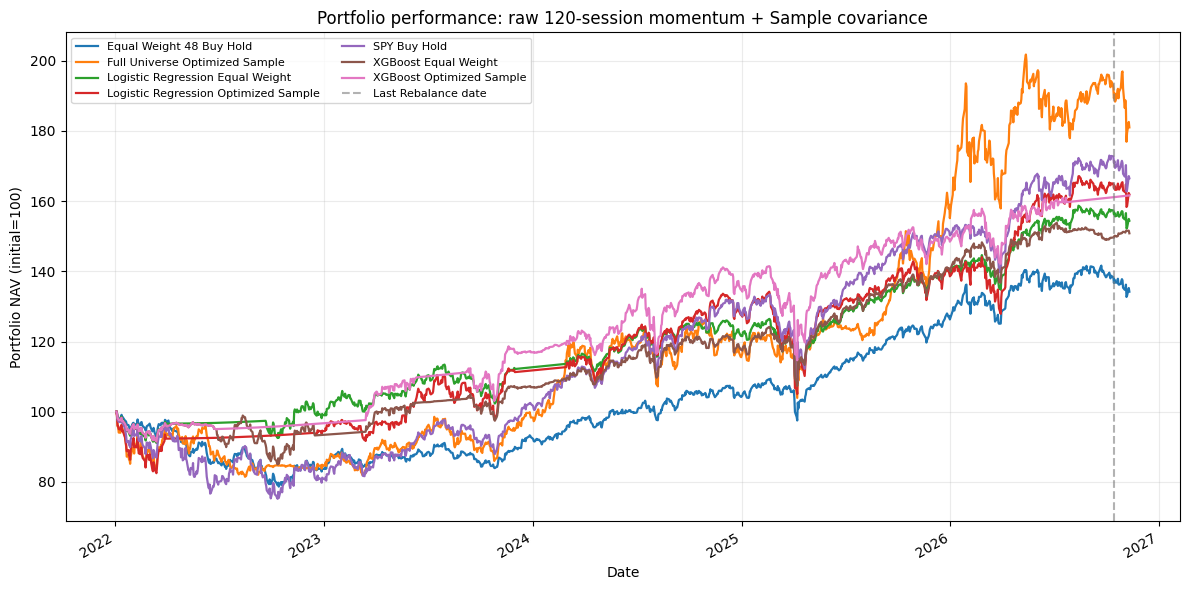

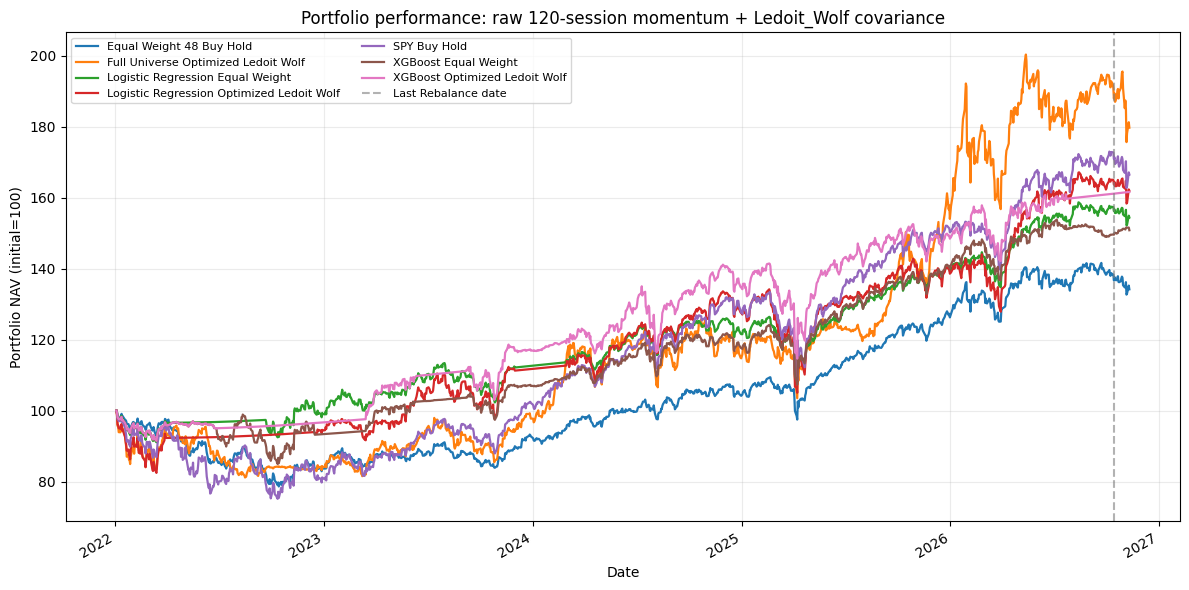

In [7]:
# Verify common valuation dates and the 20% risky-asset target-weight limit.
counts = portfolio_nav.groupby("Strategy")["Date"].nunique()
if counts.nunique() != 1:
    raise ValueError("Portfolio strategies do not share a common valuation calendar")
risky_targets = portfolio_weights.loc[portfolio_weights["Ticker"].ne(CASH_TICKER)]
non_benchmark = ~risky_targets["Strategy"].isin(["Equal_Weight_48_Buy_Hold", "SPY_Buy_Hold"])
if risky_targets.loc[non_benchmark, "Target_Weight"].gt(MAX_WEIGHT + 1e-7).any():
    raise ValueError("An allocation exceeds the 20% risky-asset cap")
if portfolio_nav["NAV"].le(0).any() or not np.isfinite(portfolio_nav["NAV"]).all():
    raise ValueError("Invalid portfolio NAV")

# Compare the original 20-period horizon with the no-rebalance extension.
primary_performance = summarize_performance(
    portfolio_nav.loc[portfolio_nav["Date"].le(primary_horizon_end)],
    portfolio_trades, INITIAL_CAPITAL, cash_return, CASH_TICKER,
)

print(f"Performance Evaluation with last day: {final_valuation_date.date()}")
display(performance_summary.sort_values("Annualized_Sharpe", ascending=False).round(4))

for covariance_method in COVARIANCE_METHODS:
    fig, ax = plt.subplots(figsize=(12, 6))
    chosen = [f"{name}_{covariance_method}" for name in strategies if name.endswith("_Optimized")]
    chosen += [name for name in strategies if not name.endswith("_Optimized")]
    group = portfolio_nav.loc[portfolio_nav["Strategy"].isin(chosen)]
    for strategy, observations in group.groupby("Strategy", sort=False):
        ax.plot(observations["Date"], 100 * observations["NAV"] / INITIAL_CAPITAL,
                label=strategy.replace("_", " "), linewidth=1.6)
    ax.axvline(primary_horizon_end, linestyle="--", color="gray", alpha=0.6,
               label="Last Rebalance date")
    ax.set(title=f"Portfolio performance: raw {EXPECTED_RETURN_LOOKBACK}-session momentum + {covariance_method} covariance",
           xlabel="Date", ylabel="Portfolio NAV (initial=100)")
    ax.legend(fontsize=8, ncol=2)
    ax.grid(alpha=0.25)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

## Export Results

In [8]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
exports = {
    "portfolio_daily_nav.csv": portfolio_nav,
    "portfolio_weights.csv": portfolio_weights,
    "portfolio_trades.csv": portfolio_trades,
    "portfolio_rebalance_summary.csv": portfolio_rebalances,
    "portfolio_performance_summary.csv": performance_summary,
}
for filename, data in exports.items():
    path = OUTPUT_DIR / filename
    data.to_csv(path, index=False)
    print(f"Saved {path}: {len(data):,} rows")

Saved portfolio_results\portfolio_daily_nav.csv: 12,190 rows
Saved portfolio_results\portfolio_weights.csv: 1,146 rows
Saved portfolio_results\portfolio_trades.csv: 1,438 rows
Saved portfolio_results\portfolio_rebalance_summary.csv: 162 rows
Saved portfolio_results\portfolio_performance_summary.csv: 10 rows
